# **Inteligencia Artificial con Aplicaciones en Economía I**

- 👩‍🏫 **Profesora:** [Lina María Castro](https://www.linkedin.com/in/lina-maria-castro)
- 📧 **Email:** [lmcastroco@gmail.com](mailto:lmcastroco@gmail.com)
- 🎓 **Universidad:** Universidad Externado de Colombia - Facultad de Economía

# 🏆 **Competencia Selección del Mejor Modelo**

**Objetivo:** Predecir las ventas de una compañía (`Sales`) teniendo en cuenta su inversión en publicidad.

**Explicación de las variables:**

- Sales: Ventas (millones USD). --> **Esta es la variable objetivo**
- TV: Gasto en promoción televisiva (millones USD).
- Radio: Gasto en promoción radiofónica (millones USD).
- Social Media: Gasto en promoción en redes sociales (millones USD).
- Influencer: Indica si la promoción se realizó en colaboración con Mega, Macro, Nano o Micro influencers.

**Nombres estudiantes del equipo:**

- Juan Sebastián Mendoza Parada
-

# **Desarrollo**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

In [2]:
pd.options.display.max_columns = None
pd.options.display.float_format = '{:,.2f}'.format

sns.set(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

### 1. Carga y exploración de los datos

In [3]:
# base de entrenamiento del repositorio del curso
url = 'https://raw.githubusercontent.com/LinaMariaCastro/curso-ia-para-economia/main/datasets/5_Aprendizaje_supervisado/train_df_ventas.csv'
ventas = pd.read_csv(url)

print(ventas.shape)
ventas.head()

(3409, 5)


,TV,Social Media,Influencer,Radio,Sales
0,25.41,3.22,Micro,22.24,262.40
1,16.84,1.58,Micro,22.24,207.19
2,24.08,6.71,Micro,22.60,233.74
3,11.50,2.52,Nano,21.42,162.32
4,8.18,0.15,Nano,22.20,114.20


In [4]:
ventas.info()

<class 'pandas.DataFrame'>
RangeIndex: 3409 entries, 0 to 3408
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   TV            3409 non-null   float64
 1   Social Media  3409 non-null   float64
 2   Influencer    3409 non-null   str    
 3   Radio         3409 non-null   float64
 4   Sales         3409 non-null   float64
dtypes: float64(4), str(1)
memory usage: 133.3 KB


In [5]:
# miramos si hay faltantes
ventas.isnull().sum()

TV              0
Social Media    0
Influencer      0
Radio           0
Sales           0
dtype: int64

In [6]:
ventas.describe()

,TV,Social Media,Radio,Sales
count,"3,409.00","3,409.00","3,409.00","3,409.00"
mean,18.10,3.34,22.09,191.55
std,9.67,2.20,0.47,93.50
min,0.00,0.00,21.03,31.20
25%,10.40,1.57,21.72,110.44
50%,17.79,3.06,22.06,188.67
75%,25.65,4.81,22.45,271.54
max,48.87,13.98,23.21,362.04


Son 3.409 observaciones y no hay datos faltantes, así que no toca limpiar nada. Sales es continua, entonces el problema es de regresión.

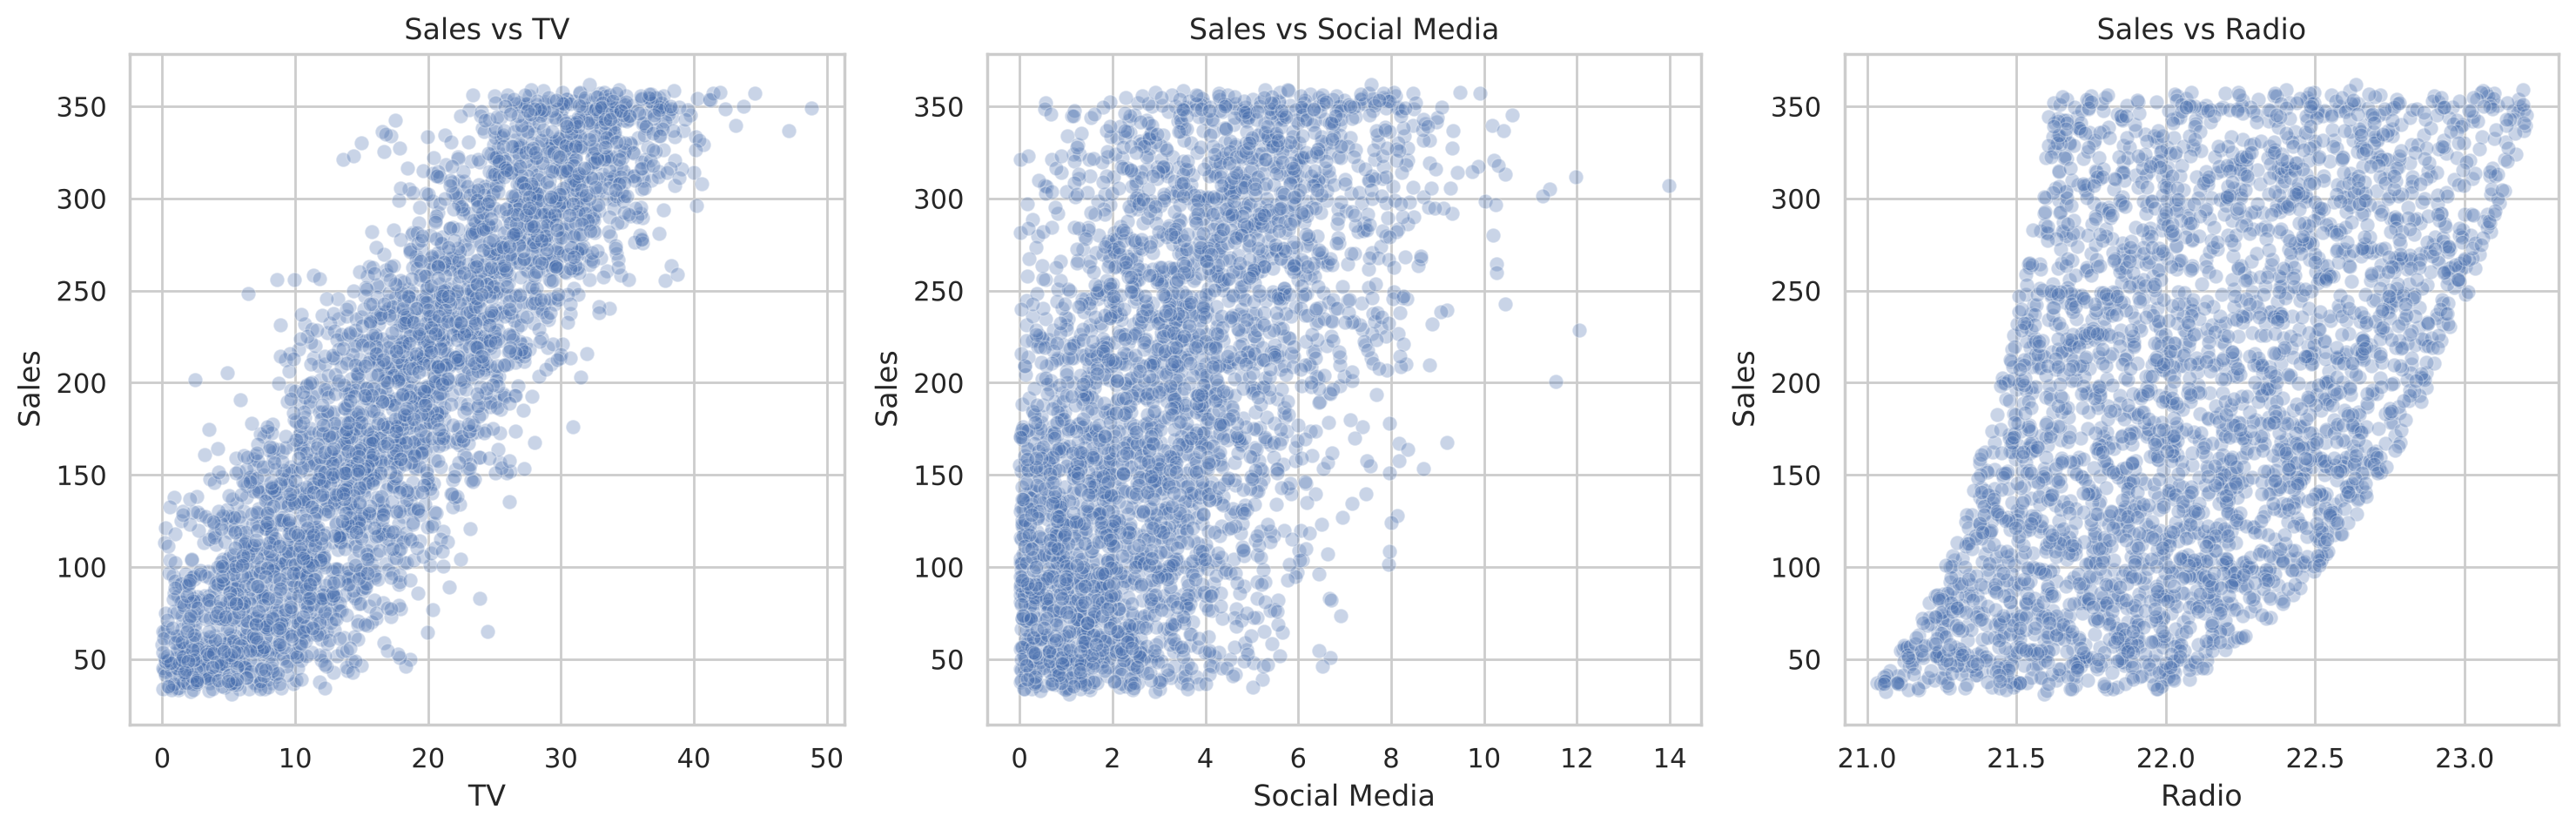

In [7]:
# cómo se relaciona cada gasto con las ventas
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, col in enumerate(['TV', 'Social Media', 'Radio']):
    sns.scatterplot(x=ventas[col], y=ventas['Sales'], alpha=0.3, ax=axes[i])
    axes[i].set_title('Sales vs ' + col)
plt.show()

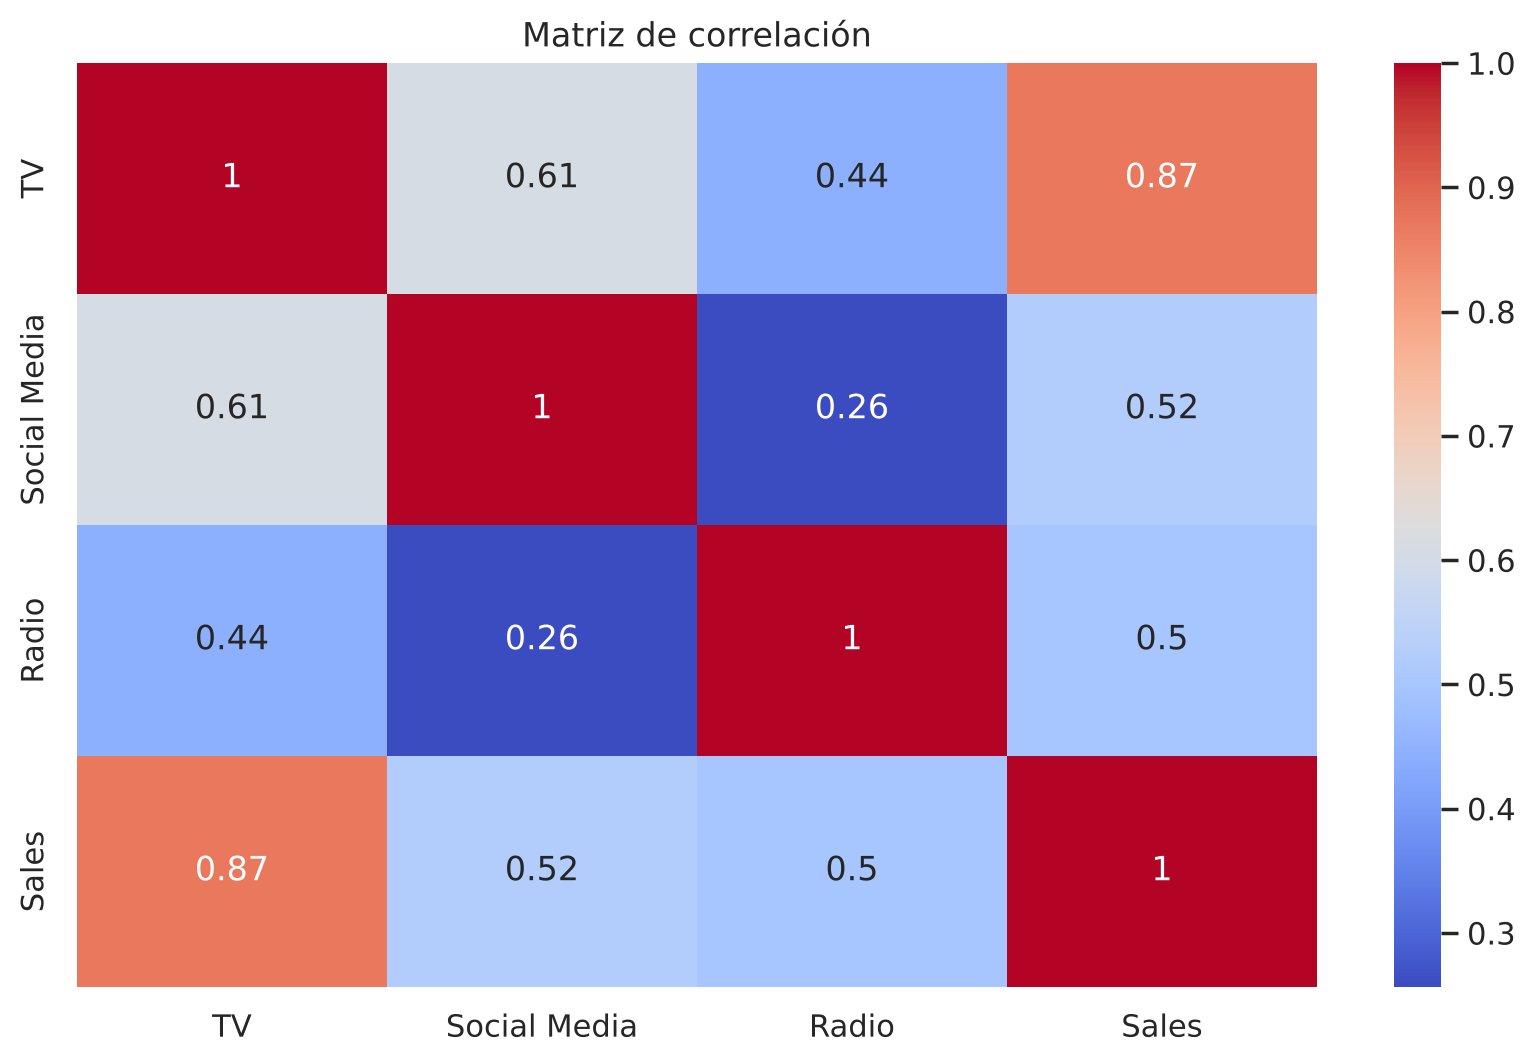

In [8]:
sns.heatmap(ventas[['TV', 'Social Media', 'Radio', 'Sales']].corr(), annot=True, cmap='coolwarm')
plt.title('Matriz de correlación')
plt.show()

TV es la variable con más relación con las ventas (correlación de 0,87). En los gráficos de dispersión la relación no se ve del todo recta: con TV las ventas se aplanan arriba de 350 y con Radio los puntos forman una franja curva. Por eso probamos modelos que puedan capturar relaciones no lineales.

In [9]:
# promedio de ventas por tipo de influencer
ventas.groupby('Influencer')['Sales'].mean()

Influencer
Macro   196.92
Mega    191.31
Micro   189.11
Nano    189.17
Name: Sales, dtype: float64

El promedio de ventas casi no cambia entre tipos de influencer (va de 189 a 197), por eso no usamos esa variable.

### 2. Preprocesamiento

In [10]:
X = ventas[['TV', 'Social Media', 'Radio']]
y = ventas['Sales']

# 80% entrenamiento y 20% prueba, con semilla
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(X_train.shape, X_test.shape)

(2727, 3) (682, 3)


### 3. Modelos

Entrenamos una regresión polinómica, porque las relaciones tienen curvas, y un Gradient Boosting. En la polinómica usamos Ridge y Lasso para controlar el sobreajuste, como en la clase de regresión polinómica.

#### Modelo 1: Regresión polinómica

In [11]:
# polinómica con Ridge
pipeline_ridge = Pipeline([
    ("poly_features", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

param_grid_ridge = {
    'poly_features__degree': [2, 3, 4, 5],
    'model__alpha': [0.1, 1, 10]
}

grid_ridge = GridSearchCV(pipeline_ridge, param_grid_ridge, cv=5,
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_ridge.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_ridge.best_params_)
print('RMSE CV:', -grid_ridge.best_score_)

Mejores hiperparámetros: {'model__alpha': 0.1, 'poly_features__degree': 4}
RMSE CV: 43.37451957080663


In [12]:
# polinómica con Lasso, con más iteraciones para que converja
pipeline_lasso = Pipeline([
    ("poly_features", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Lasso(max_iter=10000))
])

param_grid_lasso = {
    'poly_features__degree': [2, 3, 4, 5],
    'model__alpha': [0.01, 0.1, 1]
}

grid_lasso = GridSearchCV(pipeline_lasso, param_grid_lasso, cv=5,
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_lasso.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_lasso.best_params_)
print('RMSE CV:', -grid_lasso.best_score_)

Mejores hiperparámetros: {'model__alpha': 0.01, 'poly_features__degree': 5}
RMSE CV: 43.374610903856244


In [13]:
rmse_train_ridge = np.sqrt(mean_squared_error(y_train, grid_ridge.predict(X_train)))
rmse_test_ridge = np.sqrt(mean_squared_error(y_test, grid_ridge.predict(X_test)))

rmse_train_lasso = np.sqrt(mean_squared_error(y_train, grid_lasso.predict(X_train)))
rmse_test_lasso = np.sqrt(mean_squared_error(y_test, grid_lasso.predict(X_test)))

print('Ridge -> entrenamiento:', round(rmse_train_ridge, 2), '| prueba:', round(rmse_test_ridge, 2))
print('Lasso -> entrenamiento:', round(rmse_train_lasso, 2), '| prueba:', round(rmse_test_lasso, 2))

Ridge -> entrenamiento: 43.17 | prueba: 43.4
Lasso -> entrenamiento: 43.19 | prueba: 43.39


Ridge y Lasso dan prácticamente lo mismo, alrededor de 43,37 de RMSE en validación cruzada (Ridge con grado 4 y Lasso con grado 5). El error de entrenamiento y el de prueba son muy parecidos, entonces la polinómica no se está sobreajustando.

#### Modelo 2: Gradient Boosting

In [14]:
param_grid_gb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [2, 3, 4]
}

grid_gb = GridSearchCV(GradientBoostingRegressor(random_state=42), param_grid_gb, cv=5,
                       scoring='neg_root_mean_squared_error', n_jobs=-1)
grid_gb.fit(X_train, y_train)

print('Mejores hiperparámetros:', grid_gb.best_params_)
print('RMSE CV:', -grid_gb.best_score_)

Mejores hiperparámetros: {'learning_rate': 0.03, 'max_depth': 3, 'n_estimators': 200}
RMSE CV: 42.723732570104566


In [15]:
rmse_train_gb = np.sqrt(mean_squared_error(y_train, grid_gb.predict(X_train)))
rmse_test_gb = np.sqrt(mean_squared_error(y_test, grid_gb.predict(X_test)))

print('Gradient Boosting -> entrenamiento:', round(rmse_train_gb, 2), '| prueba:', round(rmse_test_gb, 2))

Gradient Boosting -> entrenamiento: 39.99 | prueba: 42.22


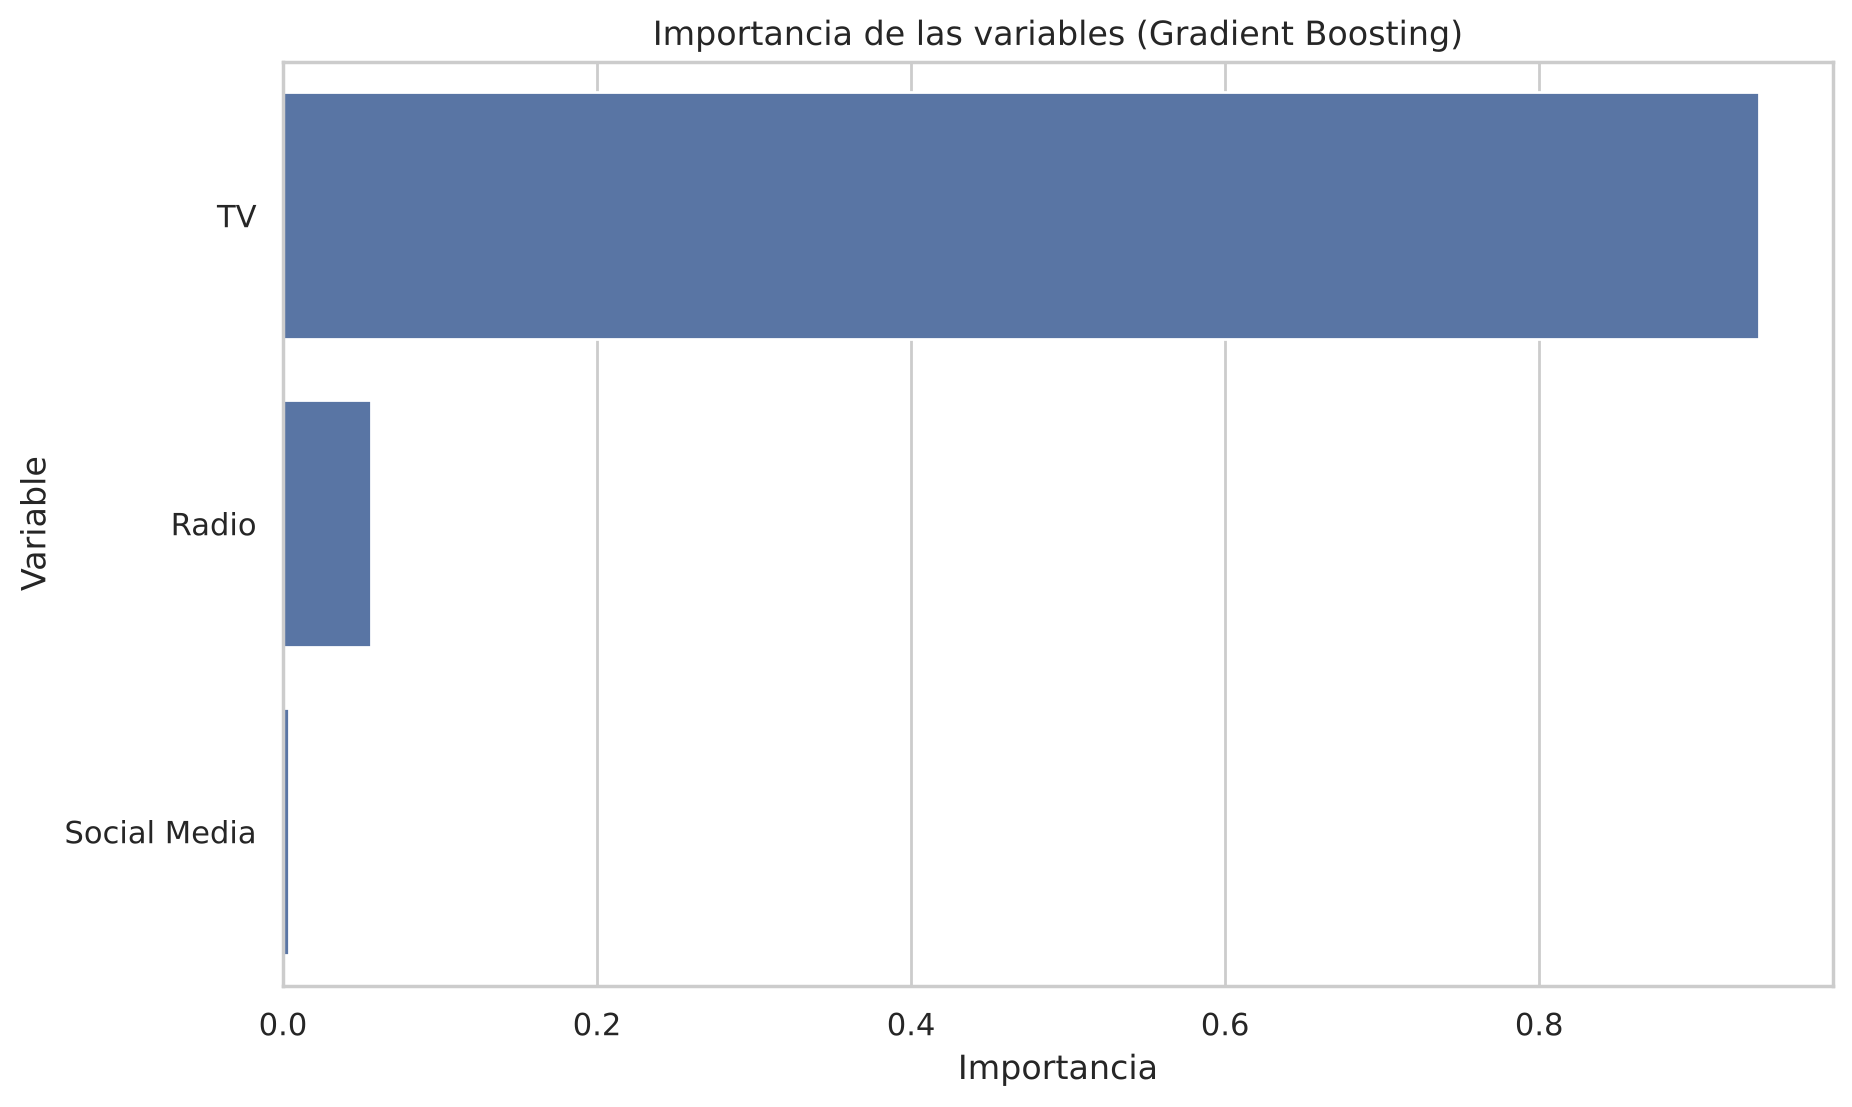

In [16]:
# importancia de cada variable en el Gradient Boosting
importancia = pd.DataFrame({
    'Variable': X.columns,
    'Importancia': grid_gb.best_estimator_.feature_importances_
}).sort_values(by='Importancia', ascending=False)

sns.barplot(x='Importancia', y='Variable', data=importancia)
plt.title('Importancia de las variables (Gradient Boosting)')
plt.show()

El Gradient Boosting baja el RMSE de validación cruzada a 42,72 y el de prueba a 42,22, menos que la polinómica. En entrenamiento el error es más bajo (39,99), o sea que se ajusta un poco más a esos datos, pero en prueba sigue siendo el mejor. TV explica casi toda la predicción (0,94 de importancia), Radio aporta algo (0,06) y Social Media casi nada.

### 4. Comparación

In [17]:
resultados = pd.DataFrame({
    'Modelo': ['Polinómica Ridge', 'Polinómica Lasso', 'Gradient Boosting'],
    'RMSE CV': [-grid_ridge.best_score_, -grid_lasso.best_score_, -grid_gb.best_score_],
    'RMSE entrenamiento': [rmse_train_ridge, rmse_train_lasso, rmse_train_gb],
    'RMSE prueba': [rmse_test_ridge, rmse_test_lasso, rmse_test_gb]
})
resultados.sort_values(by='RMSE CV')

,Modelo,RMSE CV,RMSE entrenamiento,RMSE prueba
2,Gradient Boosting,42.72,39.99,42.22
0,Polinómica Ridge,43.37,43.17,43.40
1,Polinómica Lasso,43.37,43.19,43.39


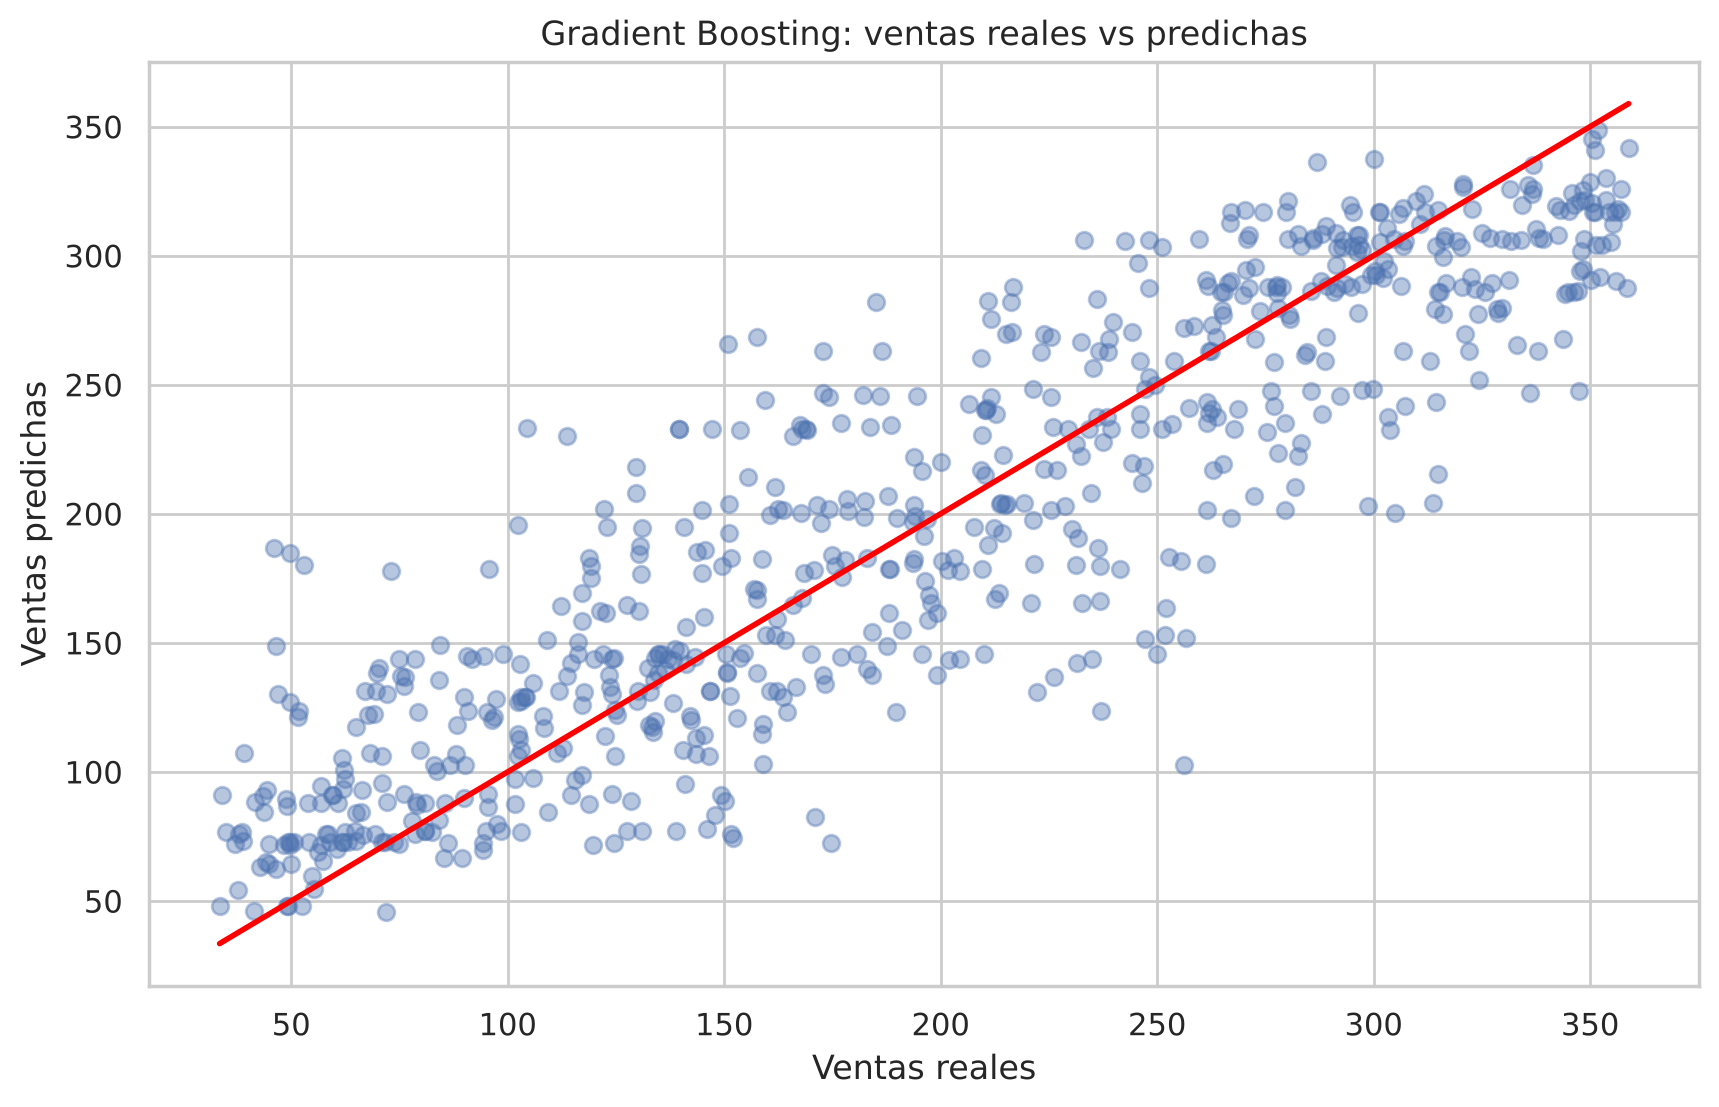

In [18]:
# predicciones del mejor modelo contra los valores reales en prueba
y_pred_gb = grid_gb.predict(X_test)

plt.scatter(y_test, y_pred_gb, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color='red', linewidth=2)
plt.title('Gradient Boosting: ventas reales vs predichas')
plt.xlabel('Ventas reales')
plt.ylabel('Ventas predichas')
plt.show()

El Gradient Boosting tiene el menor RMSE tanto en validación cruzada como en prueba. En la gráfica los puntos siguen la línea roja, aunque con bastante dispersión, porque hay una parte de las ventas que no se explica con el gasto en publicidad.

### 5. Modelo final

In [19]:
# entrenamos el modelo elegido con todos los datos de train
modelo_final = grid_gb.best_estimator_
modelo_final.fit(X, y)

# para evaluarlo en el test:
# test = pd.read_csv('test_df_ventas.csv')
# y_pred = modelo_final.predict(test[['TV', 'Social Media', 'Radio']])
# print(np.sqrt(mean_squared_error(test['Sales'], y_pred)))

,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.03
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",200
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given to each Tree estimator at eachboosting iteration.In addition, it controls the random permutation of the features ateach split (see Notes for more details).It also controls the random splitting of the training data to obtain avalidation set if `n_iter_no_change` is not None.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'This parameter has no effect... versionadded:: 0.18.. deprecated:: 1.9 `criterion` is deprecated and will be removed in 1.11.",'deprecated'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, in

# **Indique claramente cuál modelo seleccionó como el mejor**

Modelo seleccionado: **Gradient Boosting Regressor** (n_estimators = 200, learning_rate = 0,03, max_depth = 3, random_state = 42), con las variables TV, Social Media y Radio.

Lo escogimos porque fue el de menor RMSE en la validación cruzada (42,72), que es el criterio de la competencia. Las dos versiones de la regresión polinómica, con Ridge y con Lasso, quedaron en 43,37. En la partición de prueba también fue el mejor, con 42,22 frente a 43,39 de la polinómica.

El resultado tiene sentido con lo que vimos en la exploración. La relación entre la publicidad y las ventas no es lineal, y el Gradient Boosting la captura sin que tengamos que decirle qué forma tiene, porque cada árbol va corrigiendo los errores del anterior. Usamos árboles poco profundos (profundidad 3) y una tasa de aprendizaje baja para que no se sobreajuste: el error en entrenamiento (39,99) es algo menor que en prueba, pero la diferencia es pequeña.

En promedio, el modelo se equivoca en unos 42 millones de dólares al predecir las ventas. Para la entrega lo volvimos a entrenar con toda la base de entrenamiento (`modelo_final`).